# Compare SeaBee habitat GPKGs against the niche model (`nisjemodell`)

Which SeaBee layer best matches the niche model `nisjemodell_norge_2026_25833`
(output of `03`)? Using the niche model as reference lets us score **two axes** from
one overlay:

- **substrate** — SeaBee `klasse` → hard/soft vs `nkm_lm-dk`
  (`ALGAE`/`ROCK` → fastbunn, `SEDIMENT`/`ANGIO` → løsbunn; `DEEP`/`ANTHRO` excluded).
- **light** — SeaBee `klasse` → eufotisk/afotisk vs `nkm_lys`
  (shallow habitat → eufotisk, **`DEEP` → afotisk**; `ANTHRO` excluded).

Fit is area-weighted agreement over the exact polygon intersection (STRtree +
vectorised `shapely.intersection`, chunked so intersection geometries are discarded
per block). Only intersecting pairs are touched, so the comparison is restricted to
where the layers overlap. Intersections are computed once per GPKG; every axis and
scope is a mask on the resulting table.

Scopes: substrate is scored **overall** and on the **NGU**-observed subset
(`datakilde` contains `substrat_kartlagt_ngu`); light is modelled everywhere, so it is
scored overall only.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import pyarrow.fs as pafs
from concurrent.futures import ThreadPoolExecutor
import os

import mnk.rules

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

REF_URL = "niva-geodata/MarintNaturKart/results/nisjemodell_norge_2026_25833.geo.parquet"
GPKGS = {
    "direktemodell": REPO / "marint_naturkart_habitat_direktemodell_utenhb19_m2575_polygoner_uten_rutenett_norge_2024-2025_25833.gpkg",
    "regelC": REPO / "marint_naturkart_habitat_substrat_vegetasjon_regelc_polygoner_uten_rutenett_norge_2024-2025_25833.gpkg",
}
NGU_SUBSTRAT_TOKEN = "substrat_kartlagt_ngu"

A, B = 1, 2
SUB_NAME = {A: "fastbunn", B: "loesbunn"}
LYS_NAME = {A: "eufotisk", B: "afotisk"}

REF_SUB = {mnk.rules.NKM_SUBSTRAT["fast"]: A, mnk.rules.NKM_SUBSTRAT["løst"]: B}
REF_LYS = {mnk.rules.NKM_LYS["eufotisk"]: A, mnk.rules.NKM_LYS["afotisk"]: B}

_sub_token = {**mnk.rules.SEABEE_SUBSTRAT_OVERRIDE, "ANGIO": "løst"}
SEABEE_SUB = {k: (A if v == "fast" else B) for k, v in _sub_token.items()}
SEABEE_LYS = {**{k: A for k in mnk.rules.SEABEE_LYS_OVERRIDE}, "DEEP": B}

BLOCK = 50_000
SEABEE_SUB, SEABEE_LYS

({'ALGAE': 1, 'ROCK': 1, 'SEDIMENT': 2, 'ANGIO': 2},
 {'ANGIO': 1, 'ALGAE': 1, 'ROCK': 1, 'SEDIMENT': 1, 'DEEP': 2})

## 1. Load the niche model and build the index

In [2]:
fs = pafs.GcsFileSystem(anonymous=False)
ref = gpd.read_parquet(
    REF_URL, filesystem=fs, columns=["nkm_lys", "nkm_lm-dk", "datakilde", "geometry"]
)
assert ref.crs.to_epsg() == 25833
ref["ref_sub"] = ref["nkm_lm-dk"].map(REF_SUB).astype("int8")
ref["ref_lys"] = ref["nkm_lys"].map(REF_LYS).astype("int8")
ref["ref_ngu"] = ref["datakilde"].str.contains(NGU_SUBSTRAT_TOKEN, regex=False).to_numpy()
ref_tree = shapely.STRtree(ref.geometry.values)
print(f"Reference: {len(ref):,} polygons  (NGU substrate {int(ref['ref_ngu'].sum()):,})")

Reference: 2,736,485 polygons  (NGU substrate 205,861)


## 2. Load and map a SeaBee layer

`sb_sub` is NA for `DEEP`/`ANTHRO`; `sb_lys` is NA only for `ANTHRO`. Rows NA on both
(pure `ANTHRO`) are dropped.

In [3]:
def load_seabee(path):
    g = gpd.read_file(path, layer="polygons", columns=["klasse"])
    assert g.crs.to_epsg() == 25833
    g["sb_sub"] = g["klasse"].map(SEABEE_SUB).astype("Int8")
    g["sb_lys"] = g["klasse"].map(SEABEE_LYS).astype("Int8")
    return g[g["sb_sub"].notna() | g["sb_lys"].notna()].reset_index(drop=True)

## 3. Exact overlap table

SeaBee polygons are processed in chunks: each chunk is queried against the reference
index, intersected (exact, coastline preserved), and immediately **aggregated to the
distinct category combinations** so the national per-pair set is never held in memory.
Chunks run across threads — shapely releases the GIL during `intersection`/`area`.
The returned table has one row per `(sb_sub, sb_lys, sb_klasse, ref_sub, ref_lys,
ref_ngu)` combination with summed area; every downstream groupby sums these further.

In [4]:
GROUP_KEYS = ["sb_sub", "sb_lys", "sb_klasse", "ref_sub", "ref_lys", "ref_ngu"]


def _collapse(df):
    return df.groupby(GROUP_KEYS, dropna=False, sort=False)["area"].sum().reset_index()


def overlap_table(seabee, chunk=20_000, workers=None):
    sg = seabee.geometry.values
    rg = ref.geometry.values
    sb_sub = seabee["sb_sub"].to_numpy()
    sb_lys = seabee["sb_lys"].to_numpy()
    sb_klasse = seabee["klasse"].to_numpy()
    ref_sub = ref["ref_sub"].to_numpy()
    ref_lys = ref["ref_lys"].to_numpy()
    ref_ngu = ref["ref_ngu"].to_numpy()

    def do_chunk(start):
        sl = slice(start, start + chunk)
        si, ri = ref_tree.query(sg[sl], predicate="intersects")
        area = shapely.area(shapely.intersection(sg[sl][si], rg[ri]))
        keep = area > 0
        si, ri, area = si[keep], ri[keep], area[keep]
        return _collapse(pd.DataFrame({
            "sb_sub": sb_sub[sl][si],
            "sb_lys": sb_lys[sl][si],
            "sb_klasse": sb_klasse[sl][si],
            "ref_sub": ref_sub[ri],
            "ref_lys": ref_lys[ri],
            "ref_ngu": ref_ngu[ri],
            "area": area,
        }))

    parts = []
    starts = range(0, len(sg), chunk)
    with ThreadPoolExecutor(max_workers=workers or os.cpu_count()) as ex:
        for done, part in enumerate(ex.map(do_chunk, starts), 1):
            parts.append(part)
            print(f"  {min(done * chunk, len(sg)):,}/{len(sg):,} polygons", end="\r")
    print()
    return _collapse(pd.concat(parts, ignore_index=True))

## 4. Scores and confusion

Area-weighted agreement and Cohen's κ from the 2×2 confusion of any SeaBee axis
against its reference axis, over the pairs where both are defined.

In [5]:
def _conf(tab, sb_col, ref_col):
    d = tab[tab[sb_col].notna() & tab[ref_col].notna()]
    return (
        d.groupby([sb_col, ref_col])["area"].sum()
        .unstack(fill_value=0.0)
        .reindex(index=[A, B], columns=[A, B], fill_value=0.0)
    )


def scores(tab, sb_col, ref_col):
    m = _conf(tab, sb_col, ref_col).to_numpy(dtype=float)
    total = m.sum()
    po = np.trace(m) / total
    pe = (m.sum(1) @ m.sum(0)) / total**2
    return {"overlap_km2": total / 1e6, "agreement_%": po * 100, "kappa": (po - pe) / (1 - pe)}


def confmat(tab, sb_col, ref_col, names):
    c = _conf(tab, sb_col, ref_col) / 1e6
    c.index = [f"seabee_{names[i]}" for i in c.index]
    c.columns = [f"ref_{names[i]}" for i in c.columns]
    return c.round(1)

## 5. Run both layers across axes and scopes

Intersections are computed once per GPKG; scopes and axes are masks on the table.

In [6]:
DIMS = [
    ("substrate", "sb_sub", "ref_sub", SUB_NAME),
    ("light", "sb_lys", "ref_lys", LYS_NAME),
]

tables = {}
rows = []
for name, path in GPKGS.items():
    sb = load_seabee(path)
    tab = overlap_table(sb)
    tables[name] = tab
    print(f"{name}: {len(sb):,} polygons, {len(tab):,} overlap pairs")
    for dim, sb_col, ref_col, _ in DIMS:
        rows.append({"gpkg": name, "dimension": dim, "scope": "overall", **scores(tab, sb_col, ref_col)})
        if dim == "substrate":
            ngu = tab[tab["ref_ngu"]]
            rows.append({"gpkg": name, "dimension": dim, "scope": "NGU", **scores(ngu, sb_col, ref_col)})

results = pd.DataFrame(rows)

  402,850/402,850 polygons
direktemodell: 402,850 polygons, 40 overlap pairs
  249,703/249,703 polygons
regelC: 249,703 polygons, 40 overlap pairs


## 6. Results and verdict

In [7]:
results.set_index(["dimension", "scope", "gpkg"]).sort_index().round(2)

overlap_km2  agreement_%  kappa
dimension scope   gpkg                                          
light     overall direktemodell     80026.27        83.31   0.45
                  regelC            82179.29        85.83   0.52
substrate NGU     direktemodell      1001.88        53.94   0.14
                  regelC              872.39        66.54   0.34
          overall direktemodell     11338.33        58.54   0.18
                  regelC            10190.54        64.53   0.28

In [8]:
for (dim, scope), grp in results.groupby(["dimension", "scope"], sort=False):
    s = grp.sort_values("agreement_%", ascending=False)
    best, runner = s.iloc[0], s.iloc[1]
    print(
        f"{dim:>9} / {scope:<7}: {best['gpkg']} best "
        f"({best['agreement_%']:.1f}%, κ={best['kappa']:.2f}) vs "
        f"{runner['gpkg']} ({runner['agreement_%']:.1f}%)"
    )

substrate / overall: regelC best (64.5%, κ=0.28) vs direktemodell (58.5%)
substrate / NGU    : regelC best (66.5%, κ=0.34) vs direktemodell (53.9%)
    light / overall: regelC best (85.8%, κ=0.52) vs direktemodell (83.3%)


## 7. Figure — agreement by axis and scope

Grouped bars of area-weighted agreement for the two GPKGs. The taller bar in each
group is the better fit; the gap is the margin.

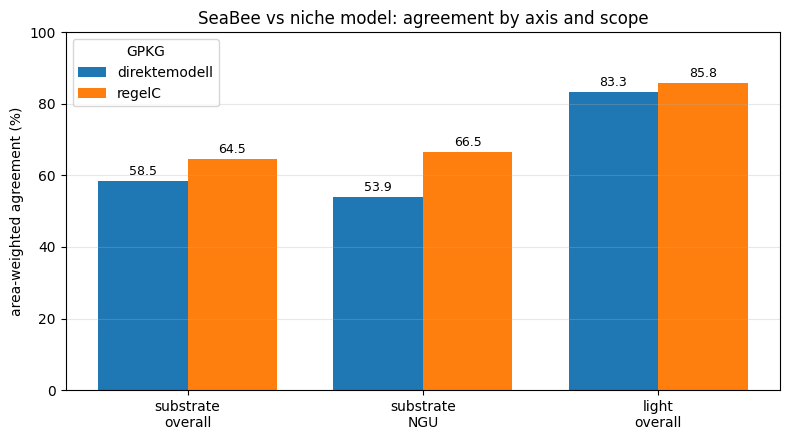

In [9]:
import matplotlib.pyplot as plt

piv = results.assign(label=results["dimension"] + "\n" + results["scope"])
labels = [l for l in ["substrate\noverall", "substrate\nNGU", "light\noverall"] if l in set(piv["label"])]
gpkgs = list(GPKGS)
x = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, name in enumerate(gpkgs):
    vals = [piv[(piv["label"] == l) & (piv["gpkg"] == name)]["agreement_%"].iloc[0] for l in labels]
    bars = ax.bar(x + (i - (len(gpkgs) - 1) / 2) * w, vals, w, label=name)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=9)

ax.set_xticks(x, labels)
ax.set_ylabel("area-weighted agreement (%)")
ax.set_ylim(0, 100)
ax.set_title("SeaBee vs niche model: agreement by axis and scope")
ax.legend(title="GPKG")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(REPO / "notebooks/scratch/compare_seabee_nisjemodell_agreement.png", dpi=150)
plt.show()

## 8. Confusion matrices (km²)

In [10]:
for name, tab in tables.items():
    for dim, sb_col, ref_col, names in DIMS:
        print(f"### {name} — {dim}")
        print(confmat(tab, sb_col, ref_col, names))
        print()

### direktemodell — substrate
                 ref_fastbunn  ref_loesbunn
seabee_fastbunn        3727.2        3046.4
seabee_loesbunn        1654.4        2910.3

### direktemodell — light
                 ref_eufotisk  ref_afotisk
seabee_eufotisk        8138.3       3200.0
seabee_afotisk        10156.2      58531.7

### regelC — substrate
                 ref_fastbunn  ref_loesbunn
seabee_fastbunn        3936.7        2063.1
seabee_loesbunn        1551.5        2639.2

### regelC — light
                 ref_eufotisk  ref_afotisk
seabee_eufotisk        8483.8       1706.7
seabee_afotisk         9938.9      62049.9



## 9. Per SeaBee class

How each SeaBee class (km²) splits across the reference axes — e.g. how much `DEEP`
area the model calls afotisk vs eufotisk, and where `ANGIO`/`SEDIMENT` disagree on
substrate.

In [11]:
def per_class(tab, ref_col, names):
    d = tab[tab[ref_col].notna()]
    t = (
        d.groupby(["sb_klasse", ref_col])["area"].sum()
        .unstack(fill_value=0.0)
        .reindex(columns=[A, B], fill_value=0.0)
        .rename(columns=names)
        / 1e6
    )
    return t.round(1)


for name, tab in tables.items():
    print(f"### {name} — class vs ref substrate (km²)")
    print(per_class(tab, "ref_sub", SUB_NAME))
    print(f"### {name} — class vs ref light (km²)")
    print(per_class(tab, "ref_lys", LYS_NAME))
    print()

### direktemodell — class vs ref substrate (km²)
ref_sub    fastbunn  loesbunn
sb_klasse                    
ALGAE        3163.2    2021.8
ANGIO         536.7     488.0
DEEP        21582.3   47105.6
ROCK          564.1    1024.6
SEDIMENT     1117.7    2422.3
### direktemodell — class vs ref light (km²)
ref_lys    eufotisk  afotisk
sb_klasse                   
ALGAE        3815.6   1369.3
ANGIO         946.9     77.8
DEEP        10156.2  58531.7
ROCK          958.7    630.0
SEDIMENT     2417.1   1122.8

### regelC — class vs ref substrate (km²)
ref_sub    fastbunn  loesbunn
sb_klasse                    
ALGAE        3666.1    1857.7
ANGIO         161.0     146.5
DEEP        21904.0   50084.8
ROCK          270.6     205.5
SEDIMENT     1390.4    2492.7
### regelC — class vs ref light (km²)
ref_lys    eufotisk  afotisk
sb_klasse                   
ALGAE        4803.0    720.8
ANGIO         254.7     52.9
DEEP         9938.9  62049.9
ROCK          418.2     57.9
SEDIMENT     3008.0    875.1

## 10. Partition sanity check

The reference is a non-overlapping partition, so per axis the overlap area must not
exceed the SeaBee layer's own mappable area for that axis. A ratio above 1 means the
SeaBee layer self-overlaps and the agreement double-counts.

In [12]:
for name, path in GPKGS.items():
    g = load_seabee(path)
    tab = tables[name]
    for dim, sb_col, _, _ in DIMS:
        sb_area = g.loc[g[sb_col].notna(), "geometry"].area.sum()
        ov = tab.loc[tab[sb_col].notna(), "area"].sum()
        print(f"{name} {dim}: mappable {sb_area/1e6:,.0f} km², overlap {ov/1e6:,.0f} km², ratio {ov/sb_area:.3f}")

direktemodell substrate: mappable 11,421 km², overlap 11,338 km², ratio 0.993
direktemodell light: mappable 80,266 km², overlap 80,026 km², ratio 0.997
regelC substrate: mappable 10,283 km², overlap 10,191 km², ratio 0.991
regelC light: mappable 82,461 km², overlap 82,179 km², ratio 0.997


## 11. Write markdown report

Assembles the summary, verdict, confusion matrices, per-class tables, and the figure
into `compare_seabee_nisjemodell_report.md` next to this notebook.

In [13]:
REPORT = REPO / "notebooks/scratch/compare_seabee_nisjemodell_report.md"

out = []
out.append("# SeaBee habitat vs niche model — substrate & light fit\n")
out.append(f"Reference: `{REF_URL}`\n")
out.append(f"Compared layers: {', '.join(f'`{g}`' for g in GPKGS)}.\n")
out.append(
    "Area-weighted agreement over exact polygon intersections, overlap only. "
    "Substrate: ALGAE/ROCK → fastbunn, SEDIMENT/ANGIO → loesbunn (DEEP/ANTHRO excluded). "
    "Light: shallow habitat → eufotisk, DEEP → afotisk (ANTHRO excluded). "
    "NGU scope restricts the reference to NGU-observed substrate.\n"
)

out.append("## Summary\n")
summary = (
    results[["dimension", "scope", "gpkg", "overlap_km2", "agreement_%", "kappa"]]
    .sort_values(["dimension", "scope", "agreement_%"], ascending=[True, True, False])
    .round(2)
)
out.append(summary.to_markdown(index=False))
out.append("")

out.append("## Verdict\n")
for (dim, scope), grp in results.groupby(["dimension", "scope"], sort=False):
    s = grp.sort_values("agreement_%", ascending=False)
    best, runner = s.iloc[0], s.iloc[1]
    out.append(
        f"- **{dim} / {scope}**: `{best['gpkg']}` fits best "
        f"({best['agreement_%']:.1f}%, κ={best['kappa']:.2f}) vs "
        f"`{runner['gpkg']}` ({runner['agreement_%']:.1f}%)."
    )
out.append("")

out.append("## Agreement by axis and scope\n")
out.append("![agreement by axis and scope](compare_seabee_nisjemodell_agreement.png)\n")

out.append("## Confusion matrices (km²)\n")
for name, tab in tables.items():
    for dim, sb_col, ref_col, names in DIMS:
        out.append(f"### {name} — {dim}\n")
        out.append(confmat(tab, sb_col, ref_col, names).to_markdown())
        out.append("")

out.append("## Per SeaBee class (km²)\n")
for name, tab in tables.items():
    out.append(f"### {name} — class vs reference substrate\n")
    out.append(per_class(tab, "ref_sub", SUB_NAME).to_markdown())
    out.append("")
    out.append(f"### {name} — class vs reference light\n")
    out.append(per_class(tab, "ref_lys", LYS_NAME).to_markdown())
    out.append("")

REPORT.write_text("\n".join(out), encoding="utf-8")
print(f"Wrote {REPORT}")

Wrote /home/kim/work/marint-naturkart-nivaR/notebooks/scratch/compare_seabee_nisjemodell_report.md
